[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/TheBestProEver/100micron-sim/blob/main/notebooks/01_two_grains_colliding.ipynb)

# 01 · Two grains colliding head-on

**The question.** Two silica grains of 100 µm diameter (radius $r$ = 50 µm) drift towards each other and touch.
What happens during the next microsecond, step by step, and why do slow grains stick while fast ones bounce?

**After this notebook you can explain**
- where the force between two sticky elastic spheres comes from: the JKR contact law, derived here from an energy
  balance, and why the contact *snaps on* when the grains touch and stretches a *neck* before it breaks;
- the phases of an impact: approach, snap-on, compression, maximum overlap, rebound, neck stretching, and then
  break (bounce) or capture (stick);
- where the impact energy goes (stored in the contact, lost to damping, lost to adhesion hysteresis), and how to
  read it off the force-overlap loop;
- what the sticking threshold is, how it is found, and how the restitution rises above it and falls again when the
  grains dent (plastic yield);
- why the model uses JKR, this damping law, plastic yield, a head-on one-dimensional impact, velocity Verlet and
  this time step.

Everything is computed by `dolle_core`, the readable core of the DOLL-E simulator. It does the same arithmetic as
the full simulator `dolle_sim`, and this notebook checks that it gives the same sticking speed and restitutions.

**Units.** SI unless stated: m, kg, s, N (newton), Pa = N/m² (pascal), J = N m (joule). For readability the plots
use µm (1e-6 m), nm (1e-9 m), µs (1e-6 s), µN (1e-6 N) and mm/s.

In [1]:
# Make the repository's packages (dolle_core, dolle_sim, and the optional extras) importable, in Colab or from a clone.
import sys, subprocess
from pathlib import Path
if "google.colab" in sys.modules:   # in Colab: install the repository from GitHub (takes ~30 s)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "git+https://github.com/TheBestProEver/100micron-sim.git"], check=True)
else:                               # locally: the repository folder is this folder or the one above (notebooks/)
    repo = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / "dolle_core").is_dir())
    sys.path.insert(0, str(repo))
    if (repo / "extras").is_dir():  # the optional v0.6 engine (extras/dolle_extras), used by the 3-D cells
        sys.path.insert(1, str(repo / "extras"))

In [2]:
import math
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
import dolle_core as dc                      # the readable core of the DOLL-E simulator
from dolle_core import nb_collisions as nb   # short plotting and bookkeeping helpers for these notebooks
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})

## 1. The two grains

A grain enters the contact physics through six numbers. They are defined in `dolle_core/materials.py`, with values
identical to the full simulator's `dolle_sim/materials.py` (checked by `tests/test_dolle_core.py`):

| symbol | meaning | unit |
|---|---|---|
| $\rho$ | density | kg/m³ |
| $E$ | Young's modulus: how stiff the solid is (stress per unit strain) | Pa |
| $\nu$ | Poisson ratio: how much the solid bulges sideways when squeezed | (none) |
| $\gamma$ | surface energy of ONE free surface: the energy needed to create 1 m² of new surface | J/m² |
| $e_{dry}$ | "dry" restitution: speed out / speed in of an impact with the stickiness switched off; it sets the damping (section 3) | (none) |
| $p_y$ | yield pressure: above it the contact dents permanently (section 11) | Pa |

In [3]:
silica = dc.get_material("silica")
print(nb.property_table(["silica"]))
print("\nsource:", silica.source)

material                rho kg/m3   E GPa    nu  gamma J/m2  e_dry  p_y GPa
silica                       2000    54.0  0.17      0.0250   0.85     3.00

source: Amorphous SiO2 spheres. gamma = 0.025 J/m^2, E = 54 GPa, nu = 0.17: the quartz values used by Chokshi, Tielens & Hollenbach (1993) ApJ 407, 806 and Dominik & Tielens (1997) ApJ 480, 647 (measured in air ~0.014-0.025 J/m^2; Kimura et al. 2015, ApJ 812, 67, argue dry silica in vacuum has ~0.15-0.25 J/m^2; Kreuzig et al. 2024, A&A 688, found no such rise for hydrophobic spheres). rho, e_dry and p_y ASSUMED.


**Why these numbers.** The source line says which values come from published work ($\gamma$, $E$, $\nu$: the quartz
values used by Chokshi, Tielens & Hollenbach 1993, ApJ 407, 806) and which the simulator ASSUMES ($\rho$, $e_{dry}$,
$p_y$). Notebook 03 discusses how uncertain each one is and how much it matters.

### Two bodies seen as one: the reduced quantities

When two spheres press on each other, the contact behaves like ONE sphere of radius $R^*$ pressing on a rigid flat
made of a material of modulus $E^*$ (Hertz 1882; Johnson 1985, *Contact Mechanics*, ch. 4):

$$\frac{1}{E^*} = \frac{1-\nu_1^2}{E_1} + \frac{1-\nu_2^2}{E_2}, \qquad R^* = \frac{r_1 r_2}{r_1 + r_2}.$$

Both bodies deform, so the contact is softer than either solid alone ($E^* < E$). A flat wall is a sphere of
infinite radius, so on a wall $R^* = r_1$.

The **reduced mass** comes from Newton's laws. Put the centres on a line at $x_1 < x_2$ and call $F$ the contact
force, positive when it pushes the grains apart. Grain 1 feels $-F$, grain 2 feels $+F$ (Newton's third law):

$$m_1 \ddot x_1 = -F,\qquad m_2 \ddot x_2 = +F \quad\Rightarrow\quad \ddot x_1 - \ddot x_2 = -F\left(\frac{1}{m_1} +
\frac{1}{m_2}\right) = -\frac{F}{m^*},\qquad m^* = \frac{m_1 m_2}{m_1 + m_2}.$$

The **overlap** $\delta = r_1 + r_2 - (x_2 - x_1)$ [m] is how far the undeformed spheres would interpenetrate
($\delta > 0$ pressed together, $\delta < 0$ pulled apart while still connected). It obeys
$m^* \ddot\delta = -F$: the collision is one body of mass $m^*$ on a (non-linear) spring. A wall has infinite mass,
so there $m^* = m_1$. Each grain's mass is $m = \frac{4}{3}\pi r^3 \rho$.

The stickiness of the pair is the **work of adhesion** $w$ [J/m²]: the energy needed to pull apart 1 m² of contact.
Pulling apart creates two free surfaces, so for one material $w = 2\gamma$. (For two materials the simulator uses
$w = 2\sqrt{\gamma_1\gamma_2}$, a mixing rule it ASSUMES; `dolle_core/pair.py`.)

In [4]:
r = 50e-6                                    # grain radius [m]: a grain of 100 um diameter
pair = dc.make_pair("silica", r, "silica", r)
print(nb.describe_pair(pair))

pair silica-silica
  E*  = 27.8035 GPa      reduced modulus
  R*  = 25.0000 um        reduced radius
  m1  = 1.0472e-09 kg,  m2 = 1.0472e-09 kg
  m*  = 5.2360e-10 kg   reduced mass
  w   = 0.05000 J/m^2     work of adhesion
  e_dry = 0.8500        dry restitution (sets the damping)
  p_y = 3.000 GPa        yield pressure


**Why this happens.** For two equal grains the formulas reduce to $E^* = E/(2(1-\nu^2))$ = 27.80 GPa, about half
of $E$ = 54 GPa because both grains deform; $R^* = r/2$ = 25 µm; $m^* = m/2$; $w = 2\gamma$ = 0.05 J/m². From here
on the contact sees only $E^*$, $R^*$, $m^*$, $w$, $e_{dry}$ and $p_y$.

## 2. The contact law: where the sticky force comes from

### 2.1 Starting point: two results of elasticity (Johnson 1985, *Contact Mechanics*, ch. 3 and 4)

Let $a$ [m] be the radius of the circular contact patch.

1. **Hertz contact (no adhesion, Hertz 1882).** A sphere $R^*$ pressed on a flat $E^*$ has
   $\delta_H = a^2/R^*$ and load $P_H = 4E^*a^3/(3R^*)$. Eliminating $a$: $P_H = \frac{4}{3}E^*\sqrt{R^*}\,\delta^{3/2}$.
   The elastic energy stored is $U_H = \int_0^\delta P_H\,d\delta' = \frac{4}{3}\cdot\frac{2}{5}E^*\sqrt{R^*}\,\delta^{5/2}
   = \frac{8E^*a^5}{15R^{*2}}$.
2. **Flat punch.** A rigid flat-ended cylinder of radius $a$ pressed into the same solid has a constant stiffness
   $dP/d\delta = 2aE^*$: the patch stays the same size, so the response is linear.

### 2.2 The JKR energy balance (Johnson, Kendall & Roberts 1971, Proc. R. Soc. A 324, 301)

Surface energy pulls the surfaces together, so at the same overlap the patch is LARGER than Hertz's. Build an
adhesive contact of patch radius $a$ in two steps:

1. press a Hertz contact until its patch has radius $a$: load $P_1 = 4E^*a^3/(3R^*)$, overlap $a^2/R^*$, energy
   $\frac{8E^*a^5}{15R^{*2}}$;
2. keeping the patch at radius $a$, pull back by a distance $D$. That is the flat punch: the load falls to
   $P = P_1 - 2aE^*D$, the overlap to $\delta = a^2/R^* - D$, and the energy released is
   $\int_0^D (P_1 - 2aE^*x)\,dx = P_1D - aE^*D^2$.

At a given overlap $\delta$ (the grains' positions held fixed) $D = a^2/R^* - \delta$, and the total energy is the
elastic energy minus the surface energy released by the patch (area $\pi a^2$, $w$ per m²):

$$U_{tot}(a;\delta) = \frac{8E^*a^5}{15R^{*2}} - P_1 D + aE^*D^2 - \pi a^2 w .$$

The patch takes the radius at which $U_{tot}$ is stationary, $\partial U_{tot}/\partial a = 0$ at fixed $\delta$.
Differentiate term by term, using $dP_1/da = 4E^*a^2/R^*$ and $dD/da = 2a/R^*$:

$$\frac{\partial}{\partial a}\frac{8E^*a^5}{15R^{*2}} = \frac{8E^*a^4}{3R^{*2}},\qquad
\frac{\partial(-P_1D)}{\partial a} = -\frac{4E^*a^2}{R^*}D - \frac{8E^*a^4}{3R^{*2}},\qquad
\frac{\partial(aE^*D^2)}{\partial a} = E^*D^2 + \frac{4E^*a^2}{R^*}D .$$

Everything cancels except $E^*D^2$, so

$$\frac{\partial U_{tot}}{\partial a} = E^*D^2 - 2\pi a w = 0 \quad\Rightarrow\quad D = \sqrt{\frac{2\pi w a}{E^*}} .$$

Putting $D$ back gives the two JKR relations:

$$\boxed{\;\delta(a) = \frac{a^2}{R^*} - \sqrt{\frac{2\pi w a}{E^*}}\;} \qquad
\boxed{\;F(a) = P_1 - 2aE^*D = \frac{4E^*a^3}{3R^*} - \sqrt{8\pi w E^* a^3}\;}$$

$F$ is the load the contact carries, positive when it pushes the grains apart. The first term of each relation is
Hertz; the second is the adhesive "neck". In the code: `dolle_core/jkr.py` `overlap_of_radius` and `force_of_radius`,
the same expressions as `dolle_sim/contact.py` `JKRContact.delta_of_a` and `force_of_a`.

**Check the derivation numerically.** Below, `nb.jkr_total_energy` evaluates $U_{tot}(a;\delta)$ exactly as written
above, and we look for its minimum over $a$ on a fine grid. The JKR relation must give the same patch radius.

In [5]:
R, w, E = pair.R_star, pair.w, pair.E_star
a_c = dc.break_radius(R, w, E)                       # smallest patch a collision can hold (section 2.3)
a = np.linspace(a_c, 1e-6, 400001)                   # trial patch radii [m]
for delta in (1e-9, 0.0, -0.5e-9):                   # overlaps [m]
    a_min = a[np.argmin(nb.jkr_total_energy(a, delta, R, w, E))]        # energy minimum
    a_jkr = dc.contact_radius(delta, R, w, E, a_guess=a_min, a_min=a_c)   # solve delta(a) = delta
    print(f"delta = {delta*1e9:+5.2f} nm: energy minimum at a = {a_min*1e9:.3f} nm, "
          f"JKR relation gives a = {a_jkr*1e9:.3f} nm")

delta = +1.00 nm: energy minimum at a = 260.571 nm, JKR relation gives a = 260.571 nm
delta = +0.00 nm: energy minimum at a = 191.857 nm, JKR relation gives a = 191.857 nm
delta = -0.50 nm: energy minimum at a = 135.968 nm, JKR relation gives a = 135.968 nm


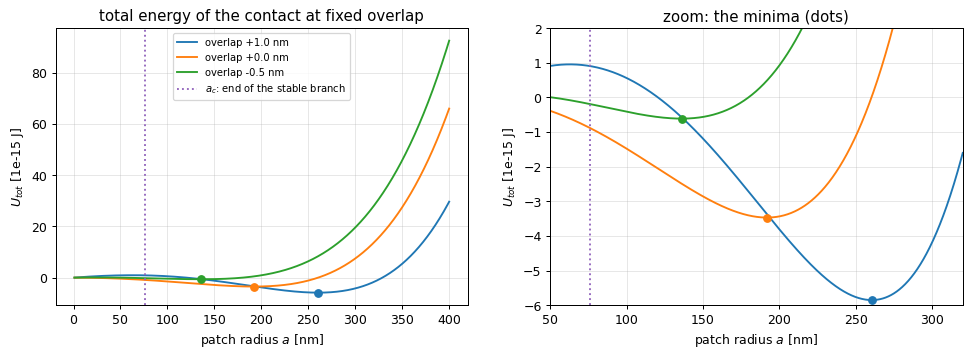

In [6]:
aa = np.linspace(1e-9, 4e-7, 2000)
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for k, delta in enumerate((1e-9, 0.0, -0.5e-9)):
    a_m = dc.contact_radius(delta, R, w, E, a_guess=2.6e-7, a_min=a_c)      # the JKR patch: the minimum
    for ax in axs:
        ax.plot(aa * 1e9, nb.jkr_total_energy(aa, delta, R, w, E) * 1e15, color=f"C{k}",
                label=f"overlap {delta*1e9:+.1f} nm")
        ax.plot(a_m * 1e9, nb.jkr_total_energy(a_m, delta, R, w, E) * 1e15, "o", color=f"C{k}")
for ax in axs:
    ax.axvline(a_c * 1e9, color="C4", ls=":", label="$a_c$: end of the stable branch")
    ax.set(xlabel="patch radius $a$ [nm]", ylabel="$U_{tot}$ [1e-15 J]")
axs[0].set_title("total energy of the contact at fixed overlap"); axs[0].legend(fontsize=8)
axs[1].set(xlim=(50, 320), ylim=(-6, 2), title="zoom: the minima (dots)"); plt.show()

**Why this happens.** The grid minimum and the JKR relation agree to the grid spacing, so the boxed relations are
the energy balance. At zero overlap the elastic energy is $E^*a^5/(5R^{*2})$ (insert $D = a^2/R^*$) while the
surface term is $-\pi a^2 w$, so at small $a$ the surface term wins and a patch of finite size forms even at zero
overlap: the grains are pulled into contact (at other overlaps the curves differ: for small $a$ the flat-punch term
$aE^*D^2 \approx aE^*\delta^2$ dominates). At
negative overlap there is still a minimum: the contact holds as a stretched neck. As the overlap falls further the
minimum gets shallower, and at the patch radius $a_c$ it disappears (next section): there the neck breaks.

### 2.3 The landmarks of the curve, step by step

Each follows from the two boxed relations by a line or two of algebra:

- **Zero load**, $F(a_0) = 0$: $\frac{4E^*a_0^3}{3R^*} = \sqrt{8\pi w E^* a_0^3}$; squaring,
  $\frac{16E^{*2}a_0^6}{9R^{*2}} = 8\pi wE^*a_0^3$, so $a_0 = \left(\frac{9\pi w R^{*2}}{2E^*}\right)^{1/3}$.
  The overlap there is $\delta(a_0) = a_0^2/(3R^*)$ (insert $a_0$: $\sqrt{2\pi w a_0/E^*} = \frac{2}{3}a_0^2/R^*$).
- **Snap-on**, $\delta(a_{snap}) = 0$: $\frac{a^2}{R^*} = \sqrt{\frac{2\pi wa}{E^*}}$, so
  $a_{snap}^3 = \frac{2\pi wR^{*2}}{E^*} = \frac{4}{9}a_0^3$. The force there is
  $\frac{4E^*}{3R^*}\cdot\frac{2\pi wR^{*2}}{E^*} - \sqrt{8\pi wE^*\cdot\frac{2\pi wR^{*2}}{E^*}} = \frac{8}{3}\pi wR^*
  - 4\pi wR^* = -\frac{4}{3}\pi w R^*$: attractive.
- **Pull-off** (the largest steady pull, $dF/da = 0$): $\frac{4E^*a^2}{R^*} = \frac{3}{2}\sqrt{8\pi wE^*}\,a^{1/2}$, so
  $a^3 = \frac{9\pi wR^{*2}}{8E^*} = a_0^3/4$, and inserting it, $F = \frac{3}{2}\pi wR^* - 3\pi wR^* = -\frac{3}{2}\pi
  wR^*$. The **pull-off force** is $F_c = \frac{3}{2}\pi w R^*$, and the snap-on force is $-\frac{8}{9}F_c$.
- **End of the stable branch** ($d\delta/da = 0$): $\frac{2a}{R^*} = \frac{1}{2}\sqrt{\frac{2\pi w}{E^*}}\,a^{-1/2}$, so
  $a_c^3 = \frac{\pi wR^{*2}}{8E^*} = a_0^3/36$, i.e. $a_c = a_0/6^{2/3}$. There $\sqrt{2\pi w/E^*} = 4a_c^{3/2}/R^*$,
  so $\delta_c = \frac{a_c^2}{R^*} - \frac{4a_c^2}{R^*} = -\frac{3a_c^2}{R^*}
  = -\frac{3}{4}\left(\frac{\pi^2w^2R^*}{E^{*2}}\right)^{1/3}$ and $F(a_c) = -\frac{5}{6}\pi wR^* = -\frac{5}{9}F_c$.
- **Why a colliding contact breaks at $a_c$.** The second derivative is
  $\frac{\partial^2U_{tot}}{\partial a^2} = 2E^*D\frac{2a}{R^*} - 2\pi w$; at equilibrium $2\pi w = E^*D^2/a$, so
  $\frac{\partial^2U_{tot}}{\partial a^2} = E^*D\left(\frac{4a}{R^*} - \frac{D}{a}\right)$. That is positive (an energy
  minimum) only while $4a^2/R^* > D = \sqrt{2\pi wa/E^*}$, i.e. $a^3 > \pi wR^{*2}/(8E^*) = a_c^3$. In a collision the
  grains' motion, not a fixed load, sets $\delta$, so the contact holds past $-F_c$ and breaks only where no
  equilibrium is left: at the **break overlap** $\delta_c$ (Chokshi, Tielens & Hollenbach 1993; Dominik & Tielens
  1997, ApJ 480, 647).

In [7]:
a0, Fc = dc.equilibrium_contact_radius(R, w, E), dc.pull_off_force(R, w)
a_snap, d_c = dc.snap_on_radius(R, w, E), dc.break_overlap(R, w, E)
F = lambda x: dc.force_of_radius(x, R, w, E)                     # F(a) [N]
print(f"a0 = {a0*1e9:.2f} nm, overlap at zero load {dc.overlap_of_radius(a0, R, w, E)*1e9:.4f} nm "
      f"= a0^2/(3R*) = {a0**2/(3*R)*1e9:.4f} nm;  F_c = 1.5 pi w R* = {Fc*1e6:.4f} uN")
print(f"snap-on:  a/a0 = {a_snap/a0:.6f} [(4/9)^(1/3) = {(4/9)**(1/3):.6f}],  F/F_c = {F(a_snap)/Fc:.6f} [-8/9]")
print(f"pull-off: a/a0 = {4**(-1/3):.6f},  F/F_c = {F(a0 / 4**(1/3))/Fc:.6f} [-1]")
print(f"break:    a/a0 = {a_c/a0:.6f} [6^(-2/3) = {6**(-2/3):.6f}],  F/F_c = {F(a_c)/Fc:.6f} [-5/9 = {-5/9:.6f}]")
print(f"break overlap delta_c = {d_c*1e9:.4f} nm;  -(3/4)(pi^2 w^2 R*/E*^2)^(1/3) = "
      f"{-0.75*(math.pi**2*w**2*R/E**2)**(1/3)*1e9:.4f} nm")

a0 = 251.40 nm, overlap at zero load 0.8427 nm = a0^2/(3R*) = 0.8427 nm;  F_c = 1.5 pi w R* = 5.8905 uN
snap-on:  a/a0 = 0.763143 [(4/9)^(1/3) = 0.763143],  F/F_c = -0.888889 [-8/9]
pull-off: a/a0 = 0.629961,  F/F_c = -1.000000 [-1]
break:    a/a0 = 0.302853 [6^(-2/3) = 0.302853],  F/F_c = -0.555556 [-5/9 = -0.555556]
break overlap delta_c = -0.6956 nm;  -(3/4)(pi^2 w^2 R*/E*^2)^(1/3) = -0.6956 nm


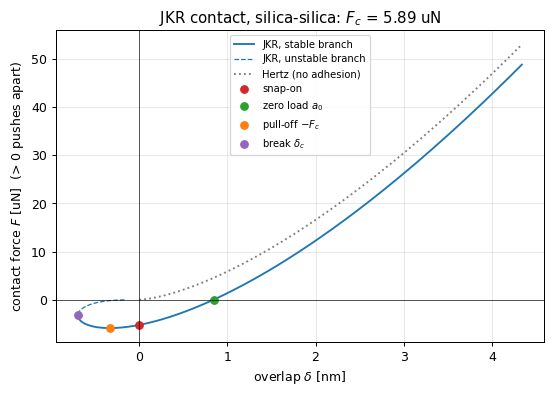

In [8]:
nb.plot_jkr_curve(pair); plt.show()

**Why this happens.** Every ratio printed above equals its closed form, so the code is the algebra. The scales are
tiny: the patch radius at zero load is a quarter of a micrometre (0.5 % of the grain radius), and the neck breaks
at an overlap of −0.7 nm, a few atomic spacings. Read the curve from the right: far in, the JKR force approaches Hertz's (the
adhesive term grows more slowly); near zero overlap it is strongly attractive; at negative overlap the stable
branch (solid) continues past the pull-off point down to the break point, where it turns back into the unstable
branch (dashed), which no collision can follow.

### 2.4 The energy kept by the contact: adhesion hysteresis $|U_0|$

The work done on the contact as it moves along the curve is $G(a) = \int F\,d\delta = \int F(a)\,\frac{d\delta}{da}\,da$.
Write $A = 4E^*/(3R^*)$, $B = \sqrt{8\pi wE^*}$, $C = \sqrt{2\pi w/E^*}$, so $F = Aa^3 - Ba^{3/2}$ and
$d\delta/da = 2a/R^* - \frac{C}{2}a^{-1/2}$. Multiplying,
$F\,\frac{d\delta}{da} = \frac{2A}{R^*}a^4 - \left(\frac{AC}{2} + \frac{2B}{R^*}\right)a^{5/2} + \frac{BC}{2}a$, and integrating
term by term

$$G(a) = \frac{2A}{5R^*}a^5 - \frac{1}{3.5}\left(\frac{AC}{2} + \frac{2B}{R^*}\right)a^{3.5} + \frac{BC}{4}a^2$$

(`dolle_core/jkr.py contact_work`, the same as `dolle_sim/contact.py _G`; note $BC/4 = \pi w$).

Follow one contact through a full cycle: the grains approach with $F = 0$ until $\delta = 0$; the patch jumps to
$a_{snap}$ without any change of $\delta$ (so no work is done on the grains; the surface energy released by the
jump leaves the bookkeeping, physically as elastic vibrations of the grains, which the model does not follow:
an interpretation, ASSUMED); the contact follows the curve in and back out along the same line; it breaks at $a_c$ and jumps to
$F = 0$. Going in and coming back out cancel, so the net work the grains must supply is the area between the neck
part of the curve (from $\delta = 0$ down to $\delta_c$) and $F = 0$:

$$|U_0| = G(a_c) - G(a_{snap}).$$

**How $|U_0|$ depends on the materials.** First simplify: $\frac{2A}{5R^*} = \frac{8E^*}{15R^{*2}}$ and
$\frac{1}{3.5}\left(\frac{AC}{2} + \frac{2B}{R^*}\right) = \frac{4}{3R^*}\sqrt{2\pi wE^*}$. Then measure the patch in units
of $a_0$, $a = s\,a_0$, and write the definition of $a_0$ as $\pi w = \frac{2E^*a_0^3}{9R^{*2}}$ (so
$\sqrt{2\pi wE^*} = \frac{2E^*}{3R^*}a_0^{3/2}$):

$$G = \frac{E^*a_0^5}{R^{*2}}\,g(s),\qquad g(s) = \frac{8s^5}{15} - \frac{8s^{7/2}}{9} + \frac{2s^2}{9},\qquad
\frac{E^*a_0^5}{R^{*2}} = \left(\frac{9\pi}{2}\right)^{5/3} w^{5/3}R^{*4/3}E^{*-2/3}.$$

The break and snap-on points are fixed fractions of $a_0$ ($s_c = 6^{-2/3}$, $s_{snap} = (4/9)^{1/3}$), so

$$|U_0| = k_U\,w^{5/3}R^{*4/3}E^{*-2/3},\qquad k_U = \left(\frac{9\pi}{2}\right)^{5/3}\left[g(6^{-2/3}) - g\big((4/9)^{1/3}\big)\right].$$

(Units alone would not fix these exponents: $wR^{*2}$ and $E^*R^{*3}$ are energies too.)

In [9]:
U0 = dc.hysteresis_energy(R, w, E)
aa = np.linspace(a_snap, a_c, 20001)                              # walk the neck part of the curve
Fa = np.array([dc.force_of_radius(x, R, w, E) for x in aa])
da = np.array([dc.overlap_of_radius(x, R, w, E) for x in aa])
area = np.sum(0.5 * (Fa[1:] + Fa[:-1]) * np.diff(da))            # trapezoidal integral of F d(delta)
g = lambda s: 8 * s**5 / 15 - 8 * s**3.5 / 9 + 2 * s**2 / 9
k_U = (4.5 * math.pi) ** (5 / 3) * (g(6 ** (-2 / 3)) - g((4 / 9) ** (1 / 3)))     # the substitution above
print(f"|U0| = G(a_c) - G(a_snap) = {U0:.6e} J;  area under the neck curve = {area:.6e} J")
print(f"k_U = {(4.5*math.pi)**(5/3):.3f} x {g(6**(-2/3)) - g((4/9)**(1/3)):.5f} = {k_U:.4f} "
      f"(dc.hysteresis_constant: {dc.hysteresis_constant():.4f}); k_U w^(5/3) R*^(4/3) E*^(-2/3) = "
      f"{k_U * w**(5/3) * R**(4/3) * E**(-2/3):.6e} J")
we = nb.well_energies(pair)                                  # in units of F_c |delta_c|
print(f"|U0| = {we['U0']:.4f} F_c|delta_c|; depth of the well from its bottom, G(a_c) - G(a0) = "
      f"{we['from_a0']:.4f} F_c|delta_c|")
print(f"kinetic energy of the relative motion at 1 mm/s: {0.5 * pair.m_star * 1e-3**2:.3e} J")

|U0| = G(a_c) - G(a_snap) = 3.833401e-15 J;  area under the neck curve = 3.833401e-15 J
k_U = 82.655 x 0.08580 = 7.0922 (dc.hysteresis_constant: 7.0922); k_U w^(5/3) R*^(4/3) E*^(-2/3) = 3.833401e-15 J
|U0| = 0.9355 F_c|delta_c|; depth of the well from its bottom, G(a_c) - G(a0) = 1.5426 F_c|delta_c|
kinetic energy of the relative motion at 1 mm/s: 2.618e-16 J


**Why this happens.** The area under the neck curve equals $G(a_c) - G(a_{snap})$, and the formula with
$k_U$ = 82.655 × 0.08580 = 7.0922 reproduces it: $|U_0|$ = 3.83e-15 J for this pair, about fifteen times the kinetic
energy of the relative motion at 1 mm/s (2.6e-16 J). An impact must bring at least $|U_0|$ to escape, which is why
slow grains stick. In units of $F_c|\delta_c|$ the hysteresis is $0.9355\,F_c|\delta_c|$ for every material. The dust
literature often quotes $1.54\,F_c\delta_c$ (e.g. Dominik & Tielens 1997): the depth of the well measured from its
bottom at $a_0$, i.e. the energy to separate a contact at rest. An arriving grain starts at the snap-on state, not at
the bottom of the well, so it has to pay only $|U_0|$.

> **Why this choice: break at $\delta_c$ ("displacement") and not at $-F_c$ ("force").**
> *Alternatives:* LAMMPS (an open-source molecular-dynamics code; its granular package does DEM, the discrete
> element method: every grain a body moved by Newton's laws, with springs at its contacts) breaks its JKR contact
> (pair_style granular jkr) at the maximum tension $-F_c$;
> the simulator offers this as `break_mode="force"`, used only for its LAMMPS cross-check.
> *Evidence:* the stability argument above, and the collision models of Chokshi et al. (1993) and Dominik &
> Tielens (1997), which break at $\delta_c$. Under a slowly growing STEADY pull (a grain on a wall pulled by the
> rocket's acceleration) the break is at $-F_c$ in either mode (the simulator's check `detachment`). *Effect:* the force rule makes the hysteresis
> smaller; the cell below prints by how much it changes the undamped sticking speed
> $v_{stick,0} = \sqrt{2|U_0|/m^*}$ (the sticking speed without damping, section 9).

In [10]:
v_disp = dc.undamped_sticking_speed(pair, mode="displacement")
v_force = dc.undamped_sticking_speed(pair, mode="force")
print(f"undamped sticking speed: break at delta_c {v_disp*1e3:.4f} mm/s, break at -F_c {v_force*1e3:.4f} mm/s, "
      f"ratio {v_disp/v_force:.5f}")

undamped sticking speed: break at delta_c 3.8266 mm/s, break at -F_c 2.6891 mm/s, ratio 1.42297


**Why this happens.** Breaking at $-F_c$ ends the neck earlier, at the larger patch $a_0/4^{1/3}$ instead of
$a_0/6^{2/3}$, so the loop above encloses less area: the hysteresis is smaller, and the undamped sticking speed
is lower by the factor 1.42297 (the same for every material, because both break points are fixed fractions of $a_0$).

> **Why this choice: JKR, and not DMT or Maugis–Dugdale.**
> Real surface forces act over a small range $z_0$ (a few tenths of a nanometre). Whether JKR applies depends on
> the **Tabor parameter** $\mu_T = \left(R^*w^2/(E^{*2}z_0^3)\right)^{1/3}$ (Tabor 1977, J. Colloid Interface Sci. 58, 2):
> the height of the neck the adhesion pulls up (of the order of $|\delta_c|$) compared with $z_0$.
> *Alternatives:* JKR is the limit of large $\mu_T$ (soft, sticky, large spheres); the DMT model (Derjaguin, Muller &
> Toporov 1975, J. Colloid Interface Sci. 53, 314) is the limit of small $\mu_T$: a Hertz contact plus an adhesive force
> acting just outside the patch, pull-off force $2\pi wR^*$, no neck; the Maugis–Dugdale model (Maugis 1992,
> J. Colloid Interface Sci. 150, 243) covers the range in between (map: Johnson & Greenwood 1997, J. Colloid
> Interface Sci. 192, 326). *Evidence:* the cell below, with $z_0$ = 0.2–0.4 nm (the range the simulator's notes
> use, PROVENANCE.md; ASSUMED). JKR is accurate above $\mu_T \approx$ 3–5 (PROVENANCE.md).

In [11]:
cases = (("silica", r, "silica", r), ("graphite", r, "graphite", r), ("silica", r, "glass_borosilicate", None))
for m1, r1, m2, r2 in cases:
    p = dc.make_pair(m1, r1, m2, r2)
    mu = [dc.tabor_parameter(p.R_star, p.w, p.E_star, z0) for z0 in (0.4e-9, 0.2e-9)]
    print(f"{p.name:32s} Tabor parameter {mu[0]:5.2f} (z0 = 0.4 nm) to {mu[1]:5.2f} (z0 = 0.2 nm)")

silica-silica                    Tabor parameter  1.08 (z0 = 0.4 nm) to  2.16 (z0 = 0.2 nm)
graphite-graphite                Tabor parameter  6.57 (z0 = 0.4 nm) to 13.13 (z0 = 0.2 nm)
silica-glass_borosilicate(wall)  Tabor parameter  1.21 (z0 = 0.4 nm) to  2.41 (z0 = 0.2 nm)


**Why this happens, and what it means.** Graphite is soft and sticky, so its neck is tall ($\mu_T$ ≈ 6.6–13): JKR
applies. Silica is stiffer and less sticky ($\mu_T$ ≈ 1–2, also on the glass wall): it sits in the JKR–DMT
transition, where JKR overstates the adhesion hysteresis, so the simulator's silica sticking speed is probably an
overestimate (PROVENANCE.md, "JKR adhesive contact"). The simulator still uses JKR for every contact because it is
the model of the published dust-collision work it builds on (Chokshi et al. 1993; Dominik & Tielens 1997; Wada et
al. 2007, ApJ 661, 320) and of LAMMPS, against which it is cross-checked; a Maugis–Dugdale collision model would
need $z_0$, which is not measured for these grains. How large the silica correction is remains **open**.

## 3. Damping: the second way energy is lost

Real solids turn part of the elastic energy of an impact into heat (internal friction, elastic waves). Without
damping a non-sticky impact would bounce back at full speed.

### 3.1 A linear spring with a dashpot (standard result, derived here)

A mass $m^*$ on a spring of stiffness $k$ [N/m] with a dashpot $c$ [kg/s]: $m^*\ddot x + c\dot x + kx = 0$. Write
$\omega_0 = \sqrt{k/m^*}$ and the damping ratio $\zeta = c/(2\sqrt{km^*})$. Starting at $x = 0$ with speed $v_{in}$,
$x(t) = \frac{v_{in}}{\omega_d}e^{-\zeta\omega_0 t}\sin\omega_d t$ with $\omega_d = \omega_0\sqrt{1-\zeta^2}$. The contact
ends when $x$ returns to 0 at $t = \pi/\omega_d$, with speed $v_{in}e^{-\zeta\omega_0\pi/\omega_d}$, so

$$e = \exp\left(-\frac{\pi\zeta}{\sqrt{1-\zeta^2}}\right)\quad\Rightarrow\quad (\ln e)^2(1-\zeta^2) = \pi^2\zeta^2
\quad\Rightarrow\quad \zeta = \frac{-\ln e}{\sqrt{(\ln e)^2+\pi^2}} .$$

The code's $\beta = \ln e/\sqrt{(\ln e)^2+\pi^2} = -\zeta$ (`dolle_core/damping.py damping_beta`), so $c = -2\beta\sqrt{km^*}$.

### 3.2 The same idea for the sticky Hertz/JKR contact

The contact's stiffness grows with the patch: from $P_H = \frac{4}{3}E^*\sqrt{R^*}\delta^{3/2}$,
$k = dP_H/d\delta = 2E^*\sqrt{R^*\delta} = 2E^*a$. With this $k$ the dashpot becomes $c = -2\beta\sqrt{2E^*a\,m^*}$. The
published form (Tsuji, Tanaka & Ishida 1992, Powder Technol. 71, 239, in the form used by the DEM codes EDEM and
LIGGGHTS) carries an extra factor $\sqrt{5/6}$:

$$F_{damp} = c_d\sqrt{a}\,\dot\delta, \qquad c_d = -2\sqrt{5/6}\,\beta\,\sqrt{2E^*m^*}\quad[\mathrm{kg\,m^{-1/2}\,s^{-1}}],$$

with $\dot\delta = v_1 - v_2$ the approach speed; it always opposes the relative motion. EDEM and LIGGGHTS are a
commercial and an open-source DEM code. Tsuji et al. wrote the same dashpot as $\eta = \alpha\sqrt{m^*k_H}\,\delta^{1/4}$
with $k_H = \frac43E^*\sqrt{R^*}$ and $\alpha$ read from a chart; with the Hertz patch $a = \sqrt{R^*\delta}$,
$2E^*a = \frac32k_H\delta^{1/2}$, so

$$c_d\sqrt{a} = 2\sqrt{5/6}\,|\beta|\sqrt{2E^*a\,m^*} = 2\sqrt{5/6}\,|\beta|\sqrt{\tfrac32k_Hm^*}\;\delta^{1/4}
= \sqrt5\,|\beta|\sqrt{k_Hm^*}\;\delta^{1/4}:$$

Tsuji's law with $\alpha = \sqrt5\,|\beta|$.

**Why the restitution cannot depend on the impact speed** (Hertz, no adhesion). The equation is
$m^*\ddot\delta = -K\delta^{3/2} - c_dR^{*1/4}\delta^{1/4}\dot\delta$ with $K = \frac43E^*\sqrt{R^*}$. Put $\delta = Dx$, $t = Ts$
and choose $T$ so that $m^*D/T^2 = KD^{3/2}$. Dividing by $KD^{3/2}$:

$$x'' = -x^{3/2} - \frac{c_dR^{*1/4}}{\sqrt{Km^*}}\,x^{1/4}x' = -x^{3/2} - \sqrt5\,|\beta|\,x^{1/4}x' .$$

The damping group contains no $D$; the impact speed only sets $D$ (choose $D$ so that $x'(0) = 1$). So every speed
gives the same rescaled impact and the same $e$, which depends on $\beta$, i.e. on $e_{dry}$, alone.

**The factor $\sqrt{5/6}$.** $\beta(e)$ is the linear-oscillator relation of section 3.1 applied to a non-linear
spring, so no factor makes it exact; $\sqrt{5/6}$ is the published choice (Tsuji et al. 1992; an analytic treatment
of the damped Hertz spring is Antypov & Elliott 2011, EPL 94, 50004, not checked here). The second cell below
finds the prefactor $k$ in $c_d = -2k\beta\sqrt{2E^*m^*}$ that returns $e_{dry}$ exactly. Using the JKR patch radius
$a$ (so the damping also acts in the neck, where $\delta < 0$) is the simulator's own adaptation
(PROVENANCE.md, "Viscoelastic damping": "that adaptation is ours"). $e_{dry}$ below 1 is clamped to at most 0.9999,
as in `dolle_sim/contact.py`; the core's one exception is $e_{dry} = 1$, which means no damping at all, as in the
3-D model.

In [12]:
print(f"silica pair: beta = {dc.damping_beta(pair.e_dry):.5f}, "
      f"c_d = {dc.damping_coefficient(pair.e_dry, pair.E_star, pair.m_star):.4e} kg m^-1/2 s^-1")
worst = 0.0
for e_dry in (0.5, 0.7, 0.85, 0.95):
    b = dc.damping_beta(e_dry)
    lin = math.exp(math.pi * b / math.sqrt(1 - b * b))            # linear spring-dashpot: exactly e_dry
    e_hz = [nb.dry_restitution("silica", e_dry, v) for v in (0.01, 0.1, 1.0)]
    worst = max(worst, max(abs(x - e_dry) for x in e_hz))
    print(f"e_dry = {e_dry:4.2f}: beta = {b:+.4f}, linear spring {lin:.4f}; non-sticky silica impact at "
          f"0.01 / 0.1 / 1 m/s: " + " / ".join(f"{x:.4f}" for x in e_hz))
print(f"largest |e - e_dry| = {worst:.1e}")

silica pair: beta = -0.05166, c_d = 5.0895e-01 kg m^-1/2 s^-1
e_dry = 0.50: beta = -0.2155, linear spring 0.5000; non-sticky silica impact at 0.01 / 0.1 / 1 m/s: 0.4994 / 0.4997 / 0.4998
e_dry = 0.70: beta = -0.1128, linear spring 0.7000; non-sticky silica impact at 0.01 / 0.1 / 1 m/s: 0.6996 / 0.6998 / 0.6999
e_dry = 0.85: beta = -0.0517, linear spring 0.8500; non-sticky silica impact at 0.01 / 0.1 / 1 m/s: 0.8499 / 0.8501 / 0.8501
e_dry = 0.95: beta = -0.0163, linear spring 0.9500; non-sticky silica impact at 0.01 / 0.1 / 1 m/s: 0.9500 / 0.9500 / 0.9500
largest |e - e_dry| = 6.1e-04


In [13]:
for e_dry in (0.5, 0.7, 0.85, 0.95):          # the prefactor k that returns e_dry exactly (bisection on k)
    k = nb.calibrated_prefactor(e_dry)
    print(f"e_dry = {e_dry:4.2f}: exact prefactor k = {k:.4f}  (sqrt(5/6) = {math.sqrt(5/6):.4f}, "
          f"difference {k / math.sqrt(5/6) - 1:+.1e}); with sqrt(5/6): e = {nb.restitution_with_prefactor(math.sqrt(5/6), e_dry):.5f}")

e_dry = 0.50: exact prefactor k = 0.9121  (sqrt(5/6) = 0.9129, difference -8.0e-04); with sqrt(5/6): e = 0.49972


e_dry = 0.70: exact prefactor k = 0.9123  (sqrt(5/6) = 0.9129, difference -6.0e-04); with sqrt(5/6): e = 0.69985


e_dry = 0.85: exact prefactor k = 0.9136  (sqrt(5/6) = 0.9129, difference +7.6e-04); with sqrt(5/6): e = 0.85011


e_dry = 0.95: exact prefactor k = 0.9128  (sqrt(5/6) = 0.9129, difference -5.9e-05); with sqrt(5/6): e = 0.95000


**Why this happens.** With the stickiness switched off ($\gamma$ = 1e-7 J/m², as in the simulator's check
`damping`), the restitution equals $e_{dry}$ to better than 1e-3 at every speed, as the rescaling argument says.
The prefactor that would return $e_{dry}$ exactly is within 0.1 % of $\sqrt{5/6}$ for every $e_{dry}$: the published
factor is the right one to that accuracy, and the residual (at most 6e-4 in $e$) measures how far it is from exact.

> **Why this choice: this damping form.**
> *Alternatives:* a constant dashpot $F = c\dot\delta$ (restitution then changes with speed, because the Hertz contact
> time does); the viscoelastic law of Brilliantov, Spahn, Hertzsch & Pöschel (1996, Phys. Rev. E 53, 5382), whose
> restitution falls with speed but which needs a dissipation constant that is not measured for these grains.
> *Evidence:* the restitution of these grains has not been measured ($e_{dry}$ is ASSUMED: 0.85 for silica, 0.7 for
> graphite), so the simulator uses the standard published form with exactly one number, calibrated so that a
> non-sticky impact returns $e_{dry}$ (cell above; the simulator's check `damping` gives e = 0.8501). *Caveat:* the
> assumed $e_{dry}$ sets most of each sticking speed (section 9 and notebook 03).

## 4. Moving the grains: the equations and the integrator

While the grains touch, each obeys Newton's second law with the contact force applied equal and opposite:

$$m_1\frac{dv_1}{dt} = -F,\qquad m_2\frac{dv_2}{dt} = +F,\qquad \frac{d\delta}{dt} = v_1 - v_2,\qquad
F = F_{el}(\delta) + c_d\sqrt{a}\,(v_1 - v_2).$$

$F_{el}$ is the JKR force at the patch radius $a(\delta)$: the code solves $\delta(a) = \delta$ for $a$ on the stable
branch by Newton's method (`dolle_core/jkr.py contact_radius`), and adds the plastic correction of section 11 when
the overlap exceeds the yield overlap.

**Velocity Verlet** (Verlet 1967, Phys. Rev. 159, 98; velocity form: Swope, Andersen, Berens & Wilson 1982,
J. Chem. Phys. 76, 637). One step of length $\Delta t$:

1. half kick: $v_i \leftarrow v_i + \frac{\Delta t}{2}\,\frac{F_i}{m_i}$ (with $F_1 = -F$, $F_2 = +F$);
2. drift: $\delta \leftarrow \delta + \Delta t\,(v_1 - v_2)$;
3. new force $F$ at the new overlap (damping with the half-step velocities);
4. half kick with the new force.

**Time step:** $\Delta t = \min(t_{Hz}, t_{osc})/300$, where $t_{Hz} = 2.87\left(m^{*2}/(R^*E^{*2}v_{in})\right)^{1/5}$ is
the duration of a Hertz impact (Johnson 1985, ch. 11) and $t_{osc} = 2\pi\sqrt{m^*/(2E^*a_0)}$ an estimate of the
contact's period: it uses the stiffness $2E^*a_0$ of a Hertz contact with patch $a_0$. The true small-oscillation
stiffness about the JKR equilibrium is
$\frac{dF}{d\delta} = \frac{dF/da}{d\delta/da} = \frac{2E^*a_0^2/R^*}{5a_0/(3R^*)} = \frac65E^*a_0$ (differentiate the boxed
relations and use $\sqrt{8\pi wE^*} = \frac{4E^*}{3R^*}a_0^{3/2}$, $\sqrt{2\pi w/E^*} = \frac{2}{3R^*}a_0^{3/2}$), so the true period
is $\sqrt{2/1.2}$ = 1.29 times longer. $t_{osc}$ only caps the step, so the shorter estimate is the safer one. 300 is
the simulator's `steps_per_contact` (`dolle_sim/contact.py _resolve_core`).

In [14]:
law = dc.contact_law(pair)                       # constants of this contact (dolle_core/collide.py)
v_in = 0.02                                      # approach speed [m/s]
t_hz = 2.87 * (law.m**2 / (law.R * law.E**2 * v_in)) ** 0.2
t_osc = 2 * math.pi * math.sqrt(law.m / (2 * law.E * law.a0))
print(f"at {v_in*1e3:.0f} mm/s: t_Hz = {t_hz*1e6:.3f} us, t_osc = {t_osc*1e6:.3f} us, "
      f"dt = {dc.time_step(law, v_in)*1e9:.3f} ns")
print(f"true period about a0 (stiffness 1.2 E* a0): {2 * math.pi * math.sqrt(law.m / (1.2 * law.E * law.a0))*1e6:.3f} us")

at 20 mm/s: t_Hz = 0.673 us, t_osc = 1.216 us, dt = 2.244 ns
true period about a0 (stiffness 1.2 E* a0): 1.570 us


**Why this happens.** At this speed the Hertz impact duration is the shorter of the two times, so it sets the step:
0.673 µs / 300 = 2.244 ns. A slower impact lasts longer ($t_{Hz} \propto v_{in}^{-1/5}$), until the estimate $t_{osc}$
(1.216 µs; the true period in the well is 1.57 µs) takes over.

> **Why this choice: velocity Verlet and 300 steps per contact.**
> *Alternatives:* explicit Euler (first order); classical Runge–Kutta (fourth order, but four force evaluations
> per step). Here the force jumps at snap-on and at the break, where any method's accuracy is set by how well it
> locates the jump (to within one step in this code), not by its order. *Evidence:* velocity Verlet needs one force
> per step; it is second order; it applies the same force to both grains in each half kick, so momentum is conserved
> exactly (notebook 02); and it is the scheme of the optional 3-D engine (`extras/dolle_extras/dem.py` run_steps), so the two models
> step alike. Without damping it is also *symplectic* (it preserves phase-space volume, which keeps the energy error
> bounded instead of drifting; Hairer, Lubich & Wanner 2003, Acta Numerica 12, 399); with damping evaluated at the
> half-step velocities the scheme as a whole is not. The core's test of the undamped Hertz impact shows the energy
> error falling as $\Delta t^2$ (`tests/test_dolle_core.py test_energy_conserved_in_the_elastic_hertz_limit`). The
> cell below shows what 300 steps per contact costs in accuracy.

In [15]:
conv = nb.threshold_convergence(pair, n_subs=(100, 300, 1000, 3000))
for n, v in conv.items():
    print(f"{n:5d} steps per contact: sticking speed {v*1e3:.5f} mm/s, relative to 3000 steps {v/conv[3000]-1:+.1e}")

  100 steps per contact: sticking speed 6.18403 mm/s, relative to 3000 steps +1.2e-03
  300 steps per contact: sticking speed 6.17906 mm/s, relative to 3000 steps +3.8e-04
 1000 steps per contact: sticking speed 6.17727 mm/s, relative to 3000 steps +8.6e-05
 3000 steps per contact: sticking speed 6.17674 mm/s, relative to 3000 steps +0.0e+00


**Why this happens.** The sticking speed settles as the step shrinks; at 300 steps per contact it is 3.8e-4 above
the 3000-step value, far below the uncertainty of the material values (notebook 03).

**Which threshold is "the" threshold?** These runs bisect to $v_{hi}/v_{lo} - 1 < 10^{-5}$. The simulator's default
(and `dc.sticking_threshold`'s) stops at $2\times10^{-3}$, so its value is good to about 0.1 %: 6.175 mm/s (tolerance
2e-3, section 9) and 6.179 mm/s (tolerance 1e-5, here) differ by that tolerance, not by physics.

## 5. One impact, step by step

Grain 1 moves at $u_1$ towards grain 2 at rest ($u_2 = 0$). We run two impacts: 5 mm/s and 20 mm/s.
`dc.collide(..., record=True)` keeps the whole time series (`trace`).

In [16]:
slow = dc.collide("silica", r, "silica", r, u1=0.005, u2=0.0)    # grain 1 at 5 mm/s onto grain 2 at rest
fast = dc.collide("silica", r, "silica", r, u1=0.020, u2=0.0)    # the same at 20 mm/s
for res in (slow, fast):
    ph = nb.impact_phases(res)
    print(f"\n{res.v_in*1e3:.0f} mm/s -> {res.outcome}, restitution e = {res.e:.4f}, {len(res.trace['t'])} steps")
    print(f"  touch: force {ph['F_touch']*1e6:+.3f} uN (= -(8/9) F_c)")
    print(f"  maximum overlap {ph['delta_max']*1e9:.3f} nm at t = {ph['t_max']*1e6:.3f} us, force {ph['F_max']*1e6:+.2f} uN")
    print(f"  rebound starts at t = {ph['t_rebound']*1e6:.3f} us")
    if ph["t_neck"] is not None:
        print(f"  overlap back to zero at t = {ph['t_neck']*1e6:.3f} us: the neck stretches")
    print(f"  end at t = {ph['t_end']*1e6:.3f} us: overlap {ph['delta_end']*1e9:+.3f} nm, force {ph['F_end']*1e6:+.3f} uN")


5 mm/s -> stick, restitution e = 0.0000, 237 steps
  touch: force -5.236 uN (= -(8/9) F_c)
  maximum overlap 1.999 nm at t = 0.497 us, force +12.25 uN
  rebound starts at t = 0.500 us
  end at t = 0.699 us: overlap +1.577 nm, force +7.236 uN

20 mm/s -> bounce, restitution e = 0.7562, 340 steps
  touch: force -5.236 uN (= -(8/9) F_c)
  maximum overlap 4.557 nm at t = 0.341 us, force +52.86 uN
  rebound starts at t = 0.341 us
  overlap back to zero at t = 0.716 us: the neck stretches
  end at t = 0.758 us: overlap -0.680 nm, force -4.083 uN


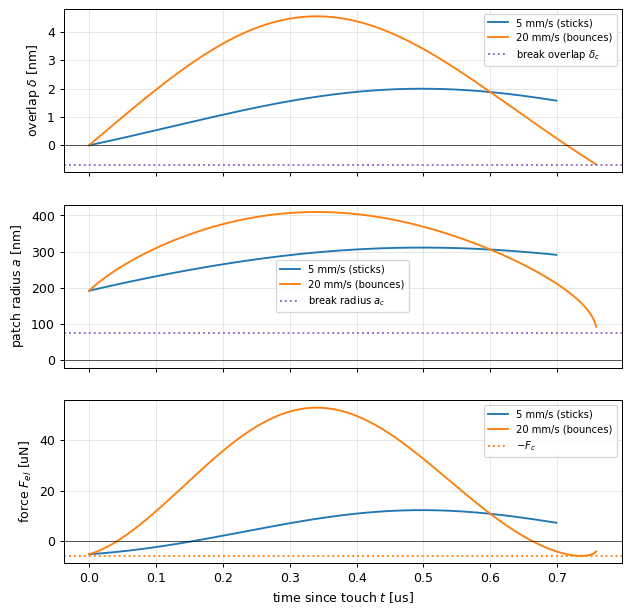

In [17]:
nb.plot_impact([slow, fast], ["5 mm/s (sticks)", "20 mm/s (bounces)"]); plt.show()

**What happens, phase by phase (the 20 mm/s impact).**

1. **Approach.** No force acts until the surfaces touch: this contact model has no force at a distance (the surface
   forces are inside the contact law).
2. **Snap-on** ($t = 0$). At $\delta = 0$ the patch jumps from nothing to $a_{snap}$ and the force to
   $-\frac{8}{9}F_c$ = −5.24 µN: adhesion pulls the grains INTO each other.
3. **Compression.** The overlap and the patch grow; the force turns repulsive once the patch is larger than $a_0$.
4. **Maximum overlap** (4.56 nm at 0.341 µs). The relative velocity is zero; the contact stores the most energy
   and pushes hardest (52.9 µN).
5. **Rebound.** The stored energy pushes the grains apart again, while the damping keeps taking energy.
6. **Neck stretching.** At 0.716 µs the overlap is back to zero, but the grains are still connected: the patch
   shrinks, the force is attractive and slows the separation.
7. **Break.** At $\delta_c$ the neck has no equilibrium left and the contact breaks; the grains fly apart with
   75.6 % of the approach speed.

**The 5 mm/s impact** starts the same way but never reaches the neck: during the rebound (from 0.500 µs) the
energy left in the relative motion plus the contact falls below the energy of a broken contact, so the grains can
never separate. The code stops there and reports a stick (section 8). In reality they would keep vibrating in the
well until the damping has stopped them.

## 6. The force-overlap loop: energy as an area

The work done on the contact is $\int F\,d\delta$, an area in the force-overlap plane. Over a closed cycle
(approach, contact, break, separated again) the enclosed area is the energy the grains lose.

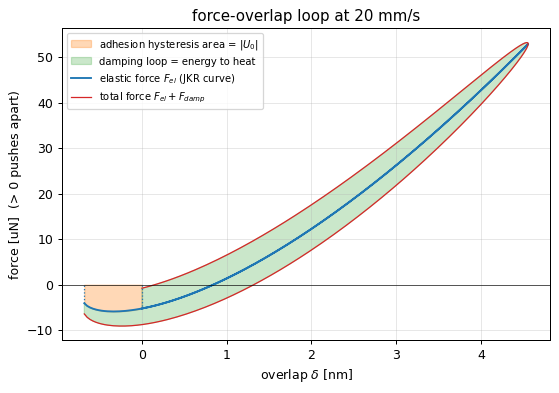

integral of F_el d(delta) over the impact:   3.7721e-15 J   (|U0| = 3.8334e-15 J)
integral of F_damp d(delta) over the impact: 4.0952e-14 J   (damping loss booked by the integrator: 4.0992e-14 J)


In [18]:
nb.plot_force_loop(fast); plt.show()
la = nb.loop_areas(fast)
print(f"integral of F_el d(delta) over the impact:   {la['elastic_work']:.4e} J   (|U0| = {la['U0']:.4e} J)")
print(f"integral of F_damp d(delta) over the impact: {la['damping_work']:.4e} J   "
      f"(damping loss booked by the integrator: {la['damping_loss_trace']:.4e} J)")

**Why this happens.** The elastic force goes in and out along the same JKR curve, so its only net area is the
orange region between the neck part of the curve and $F = 0$: the adhesion hysteresis $|U_0|$. The trapezoid sum
falls 1.6 % short of $|U_0|$ because the last step before the break ends at −0.680 nm, not exactly at
$\delta_c$ = −0.696 nm (the break is located to within one step). The total force (red) is higher on the way in
and lower on the way out because the damping always opposes the motion; the green loop between them is the energy
turned into heat, here about ten times $|U_0|$.

## 7. The energy budget

The incoming energy of the relative motion is $\frac{1}{2}m^*v_{in}^2$ (the centre-of-mass motion carries the rest
and never changes; notebook 02). During the impact it is shared between the kinetic energy of the relative motion,
the energy $U$ stored in the contact, and the two losses. Bookkeeping convention (as in the simulator): $U = 0$ for
a broken contact, so the whole $|U_0|$ is booked as lost at touch and $U$ starts at $-|U_0|$.

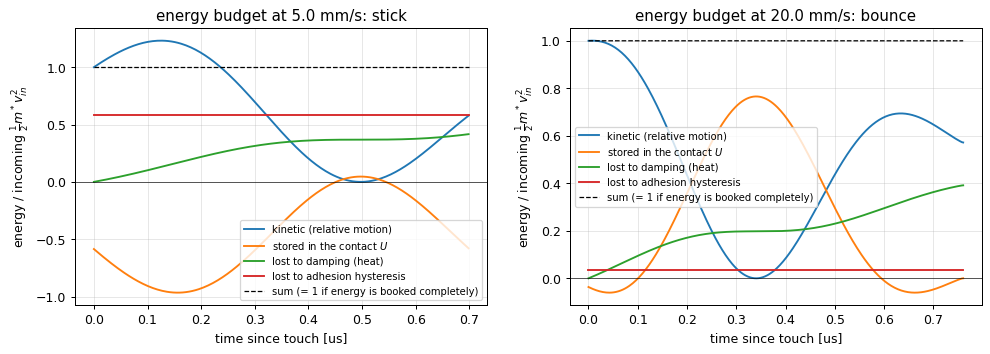

5 mm/s, E_in = 6.545e-15 J: kinetic 0.5773, stored -0.5790, damping 0.4160, hysteresis 0.5857, integrator error -1.7e-05
20 mm/s, E_in = 1.047e-13 J: kinetic 0.5719, stored +0.0000, damping 0.3914, hysteresis 0.0366, integrator error -7.6e-05
20 mm/s: e^2 = 0.5719, the kinetic fraction left after the break
5 mm/s: the kinetic energy peaks at 1.23 times the incoming energy (the grains fall into the adhesive well)


In [19]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
nb.plot_energy_budget(slow, axs[0]); nb.plot_energy_budget(fast, axs[1]); plt.show()
for res in (slow, fast):
    s = nb.energy_split(res)
    print(f"{res.v_in*1e3:.0f} mm/s, E_in = {s['E_in']:.3e} J: kinetic {s['kinetic']:.4f}, stored {s['stored']:+.4f}, "
          f"damping {s['damping_loss']:.4f}, hysteresis {s['hysteresis_loss']:.4f}, integrator error {s['energy_error']:+.1e}")
print(f"20 mm/s: e^2 = {fast.e**2:.4f}, the kinetic fraction left after the break")
print(f"5 mm/s: the kinetic energy peaks at {slow.trace['kinetic'].max() / nb.energy_split(slow)['E_in']:.2f} "
      f"times the incoming energy (the grains fall into the adhesive well)")

**Why a slow impact sticks and a fast one bounces.** The hysteresis is a FIXED cost per contact ($|U_0|$), while
the incoming energy grows as $v_{in}^2$. At 20 mm/s the hysteresis takes 3.7 % and the damping 39 %, and 57 % is
left as kinetic energy, so $e^2$ = 0.572 and $e$ = 0.756. At 5 mm/s the hysteresis alone takes 59 % and the
damping 42 % (together more than the incoming energy, which is possible because the grains are still inside the
adhesive well: the stored energy is negative). At the moment the code stops, kinetic + stored = 0.5773 − 0.5790 < 0:
the pair holds less energy than a broken contact, and damping can only lower it further, so the grains can never
escape. Note also that the slow grains first speed UP (the kinetic energy peaks at 1.23 times the incoming
energy): adhesion pulls them into the well. The integrator's
bookkeeping error is below 1e-4 of the incoming energy.

## 8. How the code decides: stick or bounce

`dolle_core/collide.py collide_pair` applies the tests of `dolle_sim/contact.py _resolve_core`, in the same order:

1. **Captured on touch:** if $\frac{1}{2}m^*v_{in}^2 < |U_0|$ the grains can never climb out of the well, even
   without damping; no integration is needed.
2. **Bounce:** after each drift, if the overlap is below the break overlap (of the flattened contact after yield,
   section 11) the contact breaks. Restitution $e$ = (separation speed at that half step) / (approach speed).
3. **Stick:** the relative velocity turned negative (rebound started) and then positive again (falling back in).
   The turn-around happens where the force is attractive, at a patch smaller than $a_0$, where $U < 0$; there the
   relative motion has no kinetic energy, so the pair holds less energy than a broken contact: it is bound.
4. **Stick:** the kinetic energy of the relative motion plus $U$ is below zero, the energy of a broken contact
   (damping can only lower it, so the break can never be reached).
5. A safety cap of 300,000 steps (never reached in these runs) counts as a stick.

The code stops as soon as test 3 or 4 has proven that the pair can never separate, while the grains are still
vibrating in the contact, and then *reports* both at the centre-of-mass velocity, where the damping would bring
them. For a stick the final velocities are therefore set by momentum conservation, not measured (notebook 02
measures them from the trace).

The model is deterministic: one impact speed, one outcome, no probabilities.

## 9. The sticking threshold

The **sticking threshold** $v_{stick}$ is the approach speed below which the pair sticks. `dc.sticking_threshold`
finds it by bisection on a logarithmic scale (midpoint $\sqrt{v_{lo}v_{hi}}$, from 1e-6 to 1 m/s, until
$v_{hi}/v_{lo} - 1 < 2\times10^{-3}$), the same search as `dolle_sim/contact.py JKRContact.threshold`. Without
damping the energy balance gives it directly: $\frac{1}{2}m^*v^2 = |U_0|$, so $v_{stick,0} = \sqrt{2|U_0|/m^*}$.

In [20]:
v_stick = dc.sticking_threshold(pair)                         # bisection on the approach speed
v_sim = nb.simulator_threshold("silica", r, "silica", r)      # the full simulator, same pair
v0 = dc.undamped_sticking_speed(pair)                         # no damping: 1/2 m* v^2 = |U0|
print(f"sticking threshold: dolle_core {v_stick*1e3:.6f} mm/s, full simulator dolle_sim {v_sim*1e3:.6f} mm/s")
print(f"without damping: sqrt(2 |U0| / m*) = {v0*1e3:.4f} mm/s; "
      f"share of the threshold energy taken by the hysteresis (v0/v_stick)^2 = {(v0/v_stick)**2:.3f}")

sticking threshold: dolle_core 6.175177 mm/s, full simulator dolle_sim 6.175177 mm/s
without damping: sqrt(2 |U0| / m*) = 3.8266 mm/s; share of the threshold energy taken by the hysteresis (v0/v_stick)^2 = 0.384


**Why this happens.** The core and the full simulator agree to every printed digit (6.175177 mm/s) because they do
the same arithmetic. Without damping two silica grains would stick below 3.83 mm/s; damping raises this to 6.18 mm/s,
because near the threshold it takes a large share of the energy. At the threshold the hysteresis takes only 38 % of
the impact energy and the damping the rest. So the ASSUMED $e_{dry}$ matters as much as the measured surface
energy (notebook 03).

## 10. Restitution against impact speed

In [21]:
speeds = np.geomspace(0.5 * v_stick, 30.0, 70)                    # approach speeds [m/s]
e, yielded = nb.restitution_curve(pair, speeds)
check = speeds[::7]                                               # 10 of them, checked against dolle_sim
e_sim = nb.simulator_restitution("silica", r, "silica", r, check)
print(f"largest |e(dolle_core) - e(dolle_sim)| at {len(check)} speeds: {np.max(np.abs(e[::7] - e_sim)):.1e}")
v_y = dc.yield_speed(pair.m_star, pair.R_star, pair.E_star, pair.p_y)
print(f"e at 2x the threshold {np.interp(2*v_stick, speeds, e):.3f}; at 0.1 m/s {np.interp(0.1, speeds, e):.3f}; "
      f"at 10 m/s {np.interp(10, speeds, e):.3f}; at 30 m/s {e[-1]:.3f}")
print(f"yield starts at v_y = {v_y:.2f} m/s; first yielded impact in the sweep at {speeds[yielded][0]:.2f} m/s")

largest |e(dolle_core) - e(dolle_sim)| at 10 speeds: 3.3e-16
e at 2x the threshold 0.671; at 0.1 m/s 0.829; at 10 m/s 0.849; at 30 m/s 0.759
yield starts at v_y = 11.13 m/s; first yielded impact in the sweep at 13.50 m/s


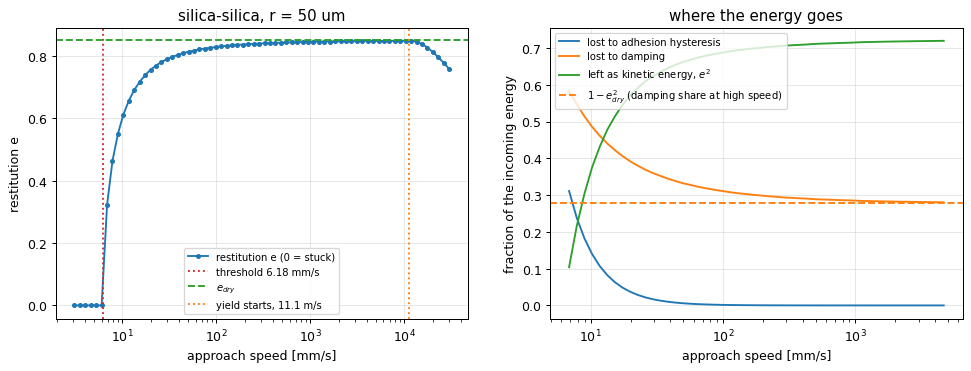

In [22]:
low = (speeds > v_stick) & (speeds < 5)                          # bouncing impacts below 5 m/s
lf = nb.loss_fractions(pair, speeds[low])
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
axs[0].semilogx(speeds * 1e3, e, ".-", label="restitution e (0 = stuck)")
axs[0].axvline(v_stick * 1e3, color="C3", ls=":", label=f"threshold {v_stick*1e3:.2f} mm/s")
axs[0].axhline(pair.e_dry, color="C2", ls="--", label="$e_{dry}$")
axs[0].axvline(v_y * 1e3, color="C1", ls=":", label=f"yield starts, {v_y:.1f} m/s")
axs[0].set(xlabel="approach speed [mm/s]", ylabel="restitution e", title="silica-silica, r = 50 um")
axs[1].semilogx(speeds[low] * 1e3, lf["hysteresis"], label="lost to adhesion hysteresis")
axs[1].semilogx(speeds[low] * 1e3, lf["damping"], label="lost to damping")
axs[1].semilogx(speeds[low] * 1e3, lf["e"] ** 2, label="left as kinetic energy, $e^2$")
axs[1].axhline(1 - pair.e_dry**2, color="C1", ls="--", label="$1 - e_{dry}^2$ (damping share at high speed)")
axs[1].set(xlabel="approach speed [mm/s]", ylabel="fraction of the incoming energy", title="where the energy goes")
for ax in axs: ax.legend(fontsize=8)
plt.show()

**Why this happens.** Just above the threshold the grains barely escape, so $e$ rises steeply from 0. Further up,
the fixed hysteresis cost becomes a smaller and smaller share (it falls as $1/v_{in}^2$), and the damping share
falls towards $1 - e_{dry}^2$, so $e$ approaches $e_{dry}$ = 0.85. Near the threshold the damping takes much MORE
than $1 - e_{dry}^2$, for two reasons that both come from adhesion: the grains fall into the adhesive well and move
faster than they arrived (section 7), and the patch never shrinks below $a_c$, so the damping force
$c_d\sqrt{a}\,\dot\delta$ keeps acting around zero overlap and in the neck, where a Hertz contact would have no patch
at all. Above $v_y$ ≈ 11 m/s the grains dent (next section) and $e$ falls again. The full simulator gives the same
restitution to rounding error.

## 11. Fast impacts: plastic yield (Thornton & Ning 1998)

Source: Thornton & Ning (1998), "A theoretical model for the stick/bounce behaviour of adhesive, elastic-plastic
spheres", Powder Technol. 99, 154. Code: `dolle_core/plastic.py`, the same as `dolle_sim/contact.py _resolve_core`.

1. **When yield starts.** In a Hertz contact the pressure is highest at the centre of the patch,
   $p_0 = \frac{3P}{2\pi a^2}$ (Johnson 1985, ch. 4); with $P = 4E^*a^3/(3R^*)$ this is $p_0 = \frac{2E^*a}{\pi R^*}$. A real
   solid cannot carry more than a limiting pressure $p_y$. Setting $p_0 = p_y$ gives $a_y = \pi R^*p_y/(2E^*)$, hence
   the **yield overlap** $\delta_y = a_y^2/R^* = R^*\left(\frac{\pi p_y}{2E^*}\right)^2$ and force
   $F_y = \frac{4}{3}E^*\sqrt{R^*}\delta_y^{3/2}$. The impact speed that just reaches it stores the Hertz energy
   $U_y = \frac{8}{15}E^*\sqrt{R^*}\delta_y^{5/2}$, so $v_y = \sqrt{2U_y/m^*}$.
2. **Loading beyond yield.** The pressure in the yielded part of the patch is capped at $p_y$. Thornton & Ning
   ASSUME that the patch area keeps growing as $\pi R^*\delta$, so each extra bit of overlap adds force at the rate
   $\pi p_y R^*$ and their (non-adhesive) loading curve is a straight line:
   $F_{max}(\delta) = F_y + \pi p_y R^*(\delta - \delta_y)$. With adhesion, the simulator's CHOICE
   (`dolle_sim/contact.py _resolve_core`, plastic branch; `dolle_core/collide.py _yield`) is to keep the JKR
   adhesive term and replace only its Hertz part by that line: $F_{el} = F_{JKR}(a) + \big(F_{max}(\delta) - F_{Hertz}(\delta)\big)$.
3. **Unloading from a flattened sphere.** From $F_y = \frac43E^*a_y^3/R^*$ and $a_y = \pi R^*p_y/(2E^*)$:
   $F_y = \frac23\pi p_y a_y^2$, so $\pi p_y R^*\delta_y = \pi p_y a_y^2 = \frac32F_y$. With $a^2 = R^*\delta$ the loading
   line is $F = F_y + \pi p_y a^2 - \frac32F_y$, so the patch at the largest force $F_{max}$ has
   $a_p^2 = \frac{2F_{max} + F_y}{2\pi p_y}$. Unloading is elastic
   (Hertz) from a sphere of a new, larger radius $R_p$ that carries $F_{max}$ on that patch:
   $R_p = \frac{4E^*a_p^3}{3F_{max}}$. It springs back by $(F_{max}/(\frac{4}{3}E^*\sqrt{R_p}))^{2/3}$, leaving a permanent
   dent $\delta_p$. From then on the contact follows the JKR relations with $R^* \to R_p$ and
   $\delta \to \delta - \delta_p$, so the flattened contact is stickier (pull-off $\frac{3}{2}\pi wR_p$).

**Check against the closed form.** Without adhesion and damping Thornton & Ning give the restitution in closed form
(`dc.thornton_ning_restitution`, quoted from their paper, not derived here, and checked numerically below); the
simulator's check `thornton_ning` uses silica with $\gamma$ = 1e-7 J/m²,
$e_{dry}$ = 0.99999 and $p_y$ = 0.5 GPa.

In [23]:
tn = replace(silica, gamma=1e-7, e_dry=0.99999, yield_pressure=0.5e9)   # the simulator's check 'thornton_ning'
p_tn = dc.make_pair(tn, r, tn, r)
v_y_tn = dc.yield_speed(p_tn.m_star, p_tn.R_star, p_tn.E_star, p_tn.p_y)
for v in (1.0, 3.0, 10.0):
    print(f"{v:4.0f} m/s: integrated e = {dc.impact(p_tn, v).e:.4f}, Thornton-Ning closed form "
          f"{dc.thornton_ning_restitution(v, v_y_tn):.4f}")
for name in ("silica", "graphite"):
    p, p_el = dc.make_pair(name, r, name, r), dc.make_pair(name, r, name, r, plastic=False)
    print(f"{name:8s} pair: yield starts at {dc.yield_speed(p.m_star, p.R_star, p.E_star, p.p_y):6.3f} m/s; "
          f"sticking threshold {dc.sticking_threshold(p)*1e3:.6f} mm/s with yield, "
          f"{dc.sticking_threshold(p_el)*1e3:.6f} mm/s without")

   1 m/s: integrated e = 0.6957, Thornton-Ning closed form 0.6957
   3 m/s: integrated e = 0.5340, Thornton-Ning closed form 0.5340
  10 m/s: integrated e = 0.3965, Thornton-Ning closed form 0.3966
silica   pair: yield starts at 11.126 m/s; sticking threshold 6.175177 mm/s with yield, 6.175177 mm/s without
graphite pair: yield starts at  0.836 m/s; sticking threshold 38.358561 mm/s with yield, 38.358561 mm/s without


**Why this happens.** The integrated impacts follow Thornton & Ning's closed form to within 1e-4, so the plastic
branch is coded as published. The yield speeds (11.1 m/s for silica, 0.84 m/s for graphite) are about 22 to 1800
times the sticking speeds, so yield never happens near the threshold, and the thresholds with and without yield are
identical.

> **Why this choice: plastic yield is included.**
> *Alternatives:* a purely elastic JKR contact. *Evidence:* the simulator must also resolve fast impacts (the
> restitution sweep above goes to 30 m/s), and there real grains dent and their restitution falls (Thornton & Ning
> 1998); without yield the model would bounce them back at about $e_{dry}$. For the sticking speeds it changes
> nothing: yield starts far above them, and the thresholds with yield on and off are identical (cell above).
> *Caveat:* every yield pressure in the table is ASSUMED.

## 12. Why a head-on, one-dimensional impact is enough for the threshold

This notebook moves the grains along one line. Real impacts are usually oblique, and then the full simulator's 3-D
contact model (the optional `extras/dolle_extras/dem.py`) also has sliding, rolling and twisting springs in the contact, and spin. The
cell below runs the simulator's own check `dem_vs_1d`: the sticking speed of head-on impacts in the 3-D model
against the 1-D model (its 1-D column is `dolle_sim/contact.py` at 2000 steps per contact and tolerance 1e-5, so
6.177 rather than this notebook's 6.175). It then repeats the 3-D silica bisection with half the step, and for
OBLIQUE impacts: the second grain displaced sideways by $r/2$ and by $r$ (normal speed $v\cos\theta$,
$\sin\theta = 0.25$ and 0.5), where the sliding and rolling springs are loaded during the contact. It needs numba
and the `extras/` folder (both available in a clone of the repository and in Colab); the first run compiles the 3-D engine (about a minute), then it takes about
half a minute.

In [24]:
try:
    import numba                                   # the 3-D engine is compiled with numba
    from dolle_extras import verify_full           # the optional v0.6 engine (extras/)
    res = verify_full.check_dem_vs_1d()            # ~10 s once compiled; the first run also compiles (~1 min)
    print(res["what"]); print("measured:", res["value"], "| criterion:", res["criterion"], "| passed:", res["passed"])
    ref = nb.simulator_threshold("silica", r, "silica", r, steps=2000, tol=1e-5)      # the check's 1-D column
    for label, kw in (("head-on, half the step", dict(dt_factor=0.5)), ("offset r/2", dict(offset=r / 2)),
                      ("offset r", dict(offset=r))):
        v3 = nb.dem_threshold("silica", r, **kw)
        print(f"silica, 3-D {label:22s}: normal sticking speed {v3*1e3:.4f} mm/s, {v3/ref - 1:+.1e} from 1-D")
except ImportError:
    print("numba or the optional extras/ folder is missing: the 3-D check cannot run here "
          "(CHECKS.md, part 2, row 1 lists its result)")

Sticking speed of head-on impacts of two 50 um grains (silica, graphite): DEM bisection vs the 1-D JKR + damping integrator of contact.py.
measured: silica 6.186 vs 6.177 mm/s; graphite 38.344 vs 38.299 mm/s; worst 1.6e-03 | criterion: < 2e-3 | passed: True


silica, 3-D head-on, half the step: normal sticking speed 6.1802 mm/s, +5.4e-04 from 1-D


silica, 3-D offset r/2            : normal sticking speed 6.1860 mm/s, +1.5e-03 from 1-D


silica, 3-D offset r              : normal sticking speed 6.1861 mm/s, +1.5e-03 from 1-D


> **Why this choice: a head-on 1-D impact for the threshold.**
> *Evidence:* for head-on impacts the 3-D model gives the same sticking speed as the 1-D model to 1.6e-3 (silica
> 6.186 vs 6.177 mm/s, graphite 38.344 vs 38.299 mm/s). Halving the 3-D step shrinks the silica gap from 1.6e-3 to
> 5e-4 (cell above), so the gap is step error of the 3-D run, not a difference in physics. That oblique impacts
> stick at the same NORMAL speed is an ASSUMPTION of the simulator's v0.5 chamber model (PROVENANCE.md, "Sticking:
> rigid aggregates", limitations); the two oblique runs above (no spin, impact offsets $r/2$ and $r$) give the
> 3-D head-on value to 1e-4 (6.1860 and 6.1861 against 6.1865 mm/s), so for these offsets it holds in the 3-D
> model. Grazing impacts, spinning grains and
> other offsets are not checked here.
> *What it does NOT cover:* spin; impacts on aggregates (the effective mass changes);
> gas drag, charging and the flight's loads on moving grains. The full simulator handles these (`dolle_sim/simulation.py`,
> and the optional `extras/dolle_extras/dem.py`); this notebook says nothing about them.

## What to remember

- The JKR contact law follows from one energy balance (elastic energy minus surface energy, stationary in the patch
  radius). It makes the grains **snap on** with $-\frac{8}{9}F_c$ and hold a **neck** down to $\delta_c < 0$.
- Making and breaking a contact costs a fixed energy $|U_0| = 7.09\,w^{5/3}R^{*4/3}E^{*-2/3}$ (adhesion hysteresis);
  damping takes a further share that, with this law, depends only on $e_{dry}$.
- A pair sticks when the impact brings too little energy to pay both. For two 100 µm silica grains this happens
  below 6.18 mm/s (3.83 mm/s without damping): at the threshold damping takes 62 % of the energy.
- Above the threshold the restitution rises towards $e_{dry}$; above the yield speed (11 m/s for silica) the grains
  dent and it falls again (Thornton & Ning).
- The readable core gives the full simulator's sticking speed and restitutions to rounding error, and the 3-D model
  gives the same head-on threshold to 1.6e-3.

## Check it yourself

Halve the grain radius to 25 µm. The undamped sticking speed scales as $R^{*-5/6}$ (notebook 03 derives this), so
**predict** the new threshold from the 50 µm value before running the cell. Then change `e_dry` instead (e.g. with
`replace(silica, e_dry=0.7)` and `dc.make_pair`) and see how far the threshold moves.

In [25]:
predicted = v_stick * 2 ** (5 / 6)                 # your prediction for r = 25 um
small = dc.make_pair("silica", 25e-6, "silica", 25e-6)
print(f"predicted {predicted*1e3:.3f} mm/s, model {dc.sticking_threshold(small)*1e3:.3f} mm/s")

predicted 11.003 mm/s, model 11.012 mm/s
